# DL_05: Comprehensive Benchmark Evaluation, Ablation Studies & Final Reporting
**Causal NLP Reasoning — Phase 2: Deep Learning**

---

## 1. Purpose and Scope
This notebook conducts the final comparative benchmarking, systematic ablation studies, and publication-ready reporting for Phase 2.

Key requirements:
- Compare Phase 1 AML baselines against Phase 2 DL (DistilBERT, PubMedBERT) and Hybrid models.
- Evaluate Corr2Cause and BioCause in completely separate evaluation sections with distinct metric tables.
- Corr2Cause must never feed into or be evaluated within the BioCause knowledge graph.
- Execute four core ablation studies: (1) Argument markers vs. no markers, (2) Weighted vs. unweighted loss, (3) AML vs. DL vs. Hybrid, and (4) Hybrid with vs. without linguistic validation.
- Evaluate graph-level edge precision, recall, and F1 against gold BioCause relations.
- Document DAG validity and causal intervention queries ($P(Y \mid do(X))$ vs. $P(Y \mid X)$).
- Export master evaluation tables and summary figures to `reports/`.


## 2. Experimental Methodology

All reported values in this notebook are computed from current prediction exports.
The model-eligible BioCause counts are 9,928 train, 1,884 validation, and 1,394
test candidates. The training positive-class weight is 9,307 / 621 = 14.9871.


## 3. Expected Inputs

The notebook consumes the current Corr2Cause, AML BioCause, PubMedBERT BioCause,
and validation-selected hybrid prediction exports. Corr2Cause is evaluated
independently and never enters BioCause fusion or graph construction.


## 4. Technical Responsibilities & Implementation Requirements

1. **Corr2Cause Evaluation (Standalone Section)**: Compute Accuracy, Macro-F1, Precision, and Recall across variable counts and templates.
2. **BioCause Benchmark (Standalone Section)**: Candidate-level classification metrics comparing AML models, PubMedBERT, and Hybrid system.
3. **Precision-Recall & ROC Analysis**: Comparative PR and ROC curves across all extraction methods.
4. **Systematic Ablation Analysis**: Execute tables for the 4 core ablation dimensions.
5. **Graph Edge Evaluation**: Compute edge precision, recall, and F1 against gold relations before and after cycle breaking.
6. **Causal Reasoning Summary**: Report Pearl's $do$-calculus interventional distributions.
7. **Master Deliverable Export**: Save final summary tables to `reports/`.


In [1]:
# Section 1: Environment Setup & Portable Imports
import sys
import os
import json
from pathlib import Path

os.environ["HF_HUB_DISABLE_IMPLICIT_TOKEN"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

def find_repo_root():
    curr = Path(os.getcwd()).resolve()
    preferred_roots = [Path('/content/causal-nlp-reasoning'), Path('/workspace/causal-nlp-reasoning'), Path('/kaggle/working/causal-nlp-reasoning')]
    search_roots = [*preferred_roots, curr, Path('/content'), Path('/workspace'), Path('/kaggle/working')]
    for base in search_roots:
        if not base.exists():
            continue
        candidates = [base, *base.parents]
        if base in {Path('/content'), Path('/workspace'), Path('/kaggle/working')}:
            candidates.extend(path.parent.parent for path in base.rglob('DL/dl_utils.py'))
        for candidate in candidates:
            if ((candidate / 'AML' / 'causal_extractors.py').is_file()
                    and (candidate / 'DL' / 'dl_utils.py').is_file()):
                return candidate.resolve()
    raise FileNotFoundError(
        'Repository root not found. Make the project folder available in the notebook workspace.'
    )

ROOT_DIR = find_repo_root()
for p in [ROOT_DIR, ROOT_DIR / 'AML', ROOT_DIR / 'DL']:
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import dl_utils
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_curve,
    auc,
    accuracy_score,
    precision_recall_fscore_support,
    average_precision_score,
    roc_auc_score,
)
import networkx as nx

dl_utils.set_seed(42)

DATA_DIR = ROOT_DIR / 'data' / 'processed'
REPORTS_DIR = ROOT_DIR / 'reports'
REPORTS_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
# Section 2: Corr2Cause Benchmark Evaluation
c2c_pred_path = DATA_DIR / 'dl_corr2cause_test_predictions.csv'
df_c2c = pd.read_csv(c2c_pred_path)
assert len(df_c2c) == dl_utils.CORR2CAUSE_SPLIT_COUNTS['test'], f'Expected 1162 rows, got {len(df_c2c)}'
assert set(df_c2c['true_label'].unique()).issubset({0, 1})
assert set(df_c2c['pred_label'].unique()).issubset({0, 1})
assert np.isfinite(df_c2c['prob_entailed'].to_numpy()).all()
assert df_c2c['prob_entailed'].between(0.0, 1.0).all()

if 'num_variables' not in df_c2c.columns and (DATA_DIR / 'dl_corr2cause_test.csv').exists():
    df_c2c_src = pd.read_csv(DATA_DIR / 'dl_corr2cause_test.csv')
    if len(df_c2c_src) == len(df_c2c) and 'num_variables' in df_c2c_src.columns:
        df_c2c['num_variables'] = df_c2c_src['num_variables'].to_numpy()

def compute_c2c_row(scope, sub_df):
    y_t = sub_df['true_label'].to_numpy()
    y_p = sub_df['pred_label'].to_numpy()
    y_prob = sub_df['prob_entailed'].to_numpy()
    cm = confusion_matrix(y_t, y_p, labels=[0, 1])
    tn, fp, fn, tp = [int(x) for x in cm.ravel()]
    p_pos, r_pos, f1_pos, _ = precision_recall_fscore_support(
        y_t, y_p, average='binary', zero_division=0
    )
    p_mac, r_mac, f1_mac, _ = precision_recall_fscore_support(
        y_t, y_p, average='macro', zero_division=0
    )
    has_two_classes = len(np.unique(y_t)) == 2
    return {
        'Scope': scope,
        'Examples': int(len(sub_df)),
        'TP': tp,
        'FP': fp,
        'FN': fn,
        'TN': tn,
        'Accuracy': float(accuracy_score(y_t, y_p)),
        'Pos Precision': float(p_pos),
        'Pos Recall': float(r_pos),
        'Pos F1': float(f1_pos),
        'Macro Precision': float(p_mac),
        'Macro Recall': float(r_mac),
        'Macro F1': float(f1_mac),
        'ROC-AUC': float(roc_auc_score(y_t, y_prob)) if has_two_classes else None,
        'PR-AUC': float(average_precision_score(y_t, y_prob)) if has_two_classes else None,
    }

c2c_rows = [compute_c2c_row('Overall (all variables)', df_c2c)]
if 'num_variables' in df_c2c.columns:
    for nv in sorted(df_c2c['num_variables'].unique()):
        c2c_rows.append(
            compute_c2c_row(f'num_variables = {int(nv)}', df_c2c[df_c2c['num_variables'] == nv])
        )

df_c2c_summary = pd.DataFrame(c2c_rows)
df_c2c_summary.round(4)


,Scope,Examples,TP,FP,FN,TN,Accuracy,Pos Precision,Pos Recall,Pos F1,Macro Precision,Macro Recall,Macro F1,ROC-AUC,PR-AUC
0,Overall (all variables),1162,68,37,112,945,0.8718,0.6476,0.3778,0.4772,0.7708,0.6700,0.7021,0.8794,0.5957
1,num_variables = 2,6,0,1,0,5,0.8333,0.0000,0.0000,0.0000,0.5000,0.4167,0.4545,NaN,NaN
2,num_variables = 3,48,3,7,0,38,0.8542,0.3000,1.0000,0.4615,0.6500,0.9222,0.6886,0.9778,0.8333
3,num_variables = 4,72,0,1,0,71,0.9861,0.0000,0.0000,0.0000,0.5000,0.4931,0.4965,NaN,NaN
4,num_variables = 5,514,36,22,21,435,0.9163,0.6207,0.6316,0.6261,0.7873,0.7917,0.7895,0.9423,0.7074
5,num_variables = 6,522,29,6,91,396,0.8142,0.8286,0.2417,0.3742,0.8209,0.6134,0.6325,0.7666,0.5497


In [3]:
# Section 3: BioCause Candidate-Level Benchmark
df_aml = pd.read_csv(DATA_DIR / 'aml_biocause_test_predictions.csv')
df_dl = pd.read_csv(DATA_DIR / 'dl_biocause_test_predictions.csv')
df_hybrid = pd.read_csv(DATA_DIR / 'dl_biocause_hybrid_test_predictions.csv')
df_test_manifest = pd.read_csv(DATA_DIR / 'dl_biocause_test.csv', keep_default_na=False)
fusion_config = json.loads((DATA_DIR / 'dl_biocause_fusion_config.json').read_text())

assert len(df_aml) == len(df_dl) == len(df_hybrid) == len(df_test_manifest) == 1394
assert (df_aml['candidate_id'].to_numpy() == df_test_manifest['candidate_id'].to_numpy()).all()
assert (df_aml['candidate_id'].to_numpy() == df_dl['candidate_id'].to_numpy()).all()
assert (df_aml['candidate_id'].to_numpy() == df_hybrid['candidate_id'].to_numpy()).all()
assert (df_aml['true_label'].to_numpy() == df_test_manifest['label'].to_numpy()).all()
assert (df_aml['true_label'].to_numpy() == df_dl['true_label'].to_numpy()).all()
assert (df_aml['true_label'].to_numpy() == df_hybrid['true_label'].to_numpy()).all()

y_true_bio = df_test_manifest['label'].to_numpy()
assert int((y_true_bio == 1).sum()) == 100 and int((y_true_bio == 0).sum()) == 1294
for prob_series, col_name in [
    (df_aml['aml_prob'], 'aml_prob'),
    (df_dl['dl_prob'], 'dl_prob'),
    (df_hybrid['hybrid_prob'], 'hybrid_prob'),
]:
    assert np.isfinite(prob_series.to_numpy()).all(), f'Non-finite values in {col_name}'
    assert prob_series.between(0.0, 1.0).all(), f'Out-of-range values in {col_name}'

selected_alpha = float(fusion_config['alpha_star'])
selected_tau = float(fusion_config['threshold_star'])
aml_selected_tau = float(fusion_config.get('aml_threshold_star', 0.50))
dl_selected_tau = float(fusion_config.get('dl_threshold_star', 0.10))

dl_metrics_file = DATA_DIR / 'dl_biocause_metrics.json'
dl_metrics_meta = None
if dl_metrics_file.is_file():
    dl_metrics_meta = json.loads(dl_metrics_file.read_text())
    assert np.isclose(dl_selected_tau, float(dl_metrics_meta['selected_threshold']), atol=1e-4), (
        f"dl_threshold_star ({dl_selected_tau}) != DL_03 selected_threshold ({dl_metrics_meta['selected_threshold']})"
    )
assert np.array_equal(
    (df_dl['dl_prob'].to_numpy() >= dl_selected_tau).astype(int),
    df_dl['dl_pred'].to_numpy(),
), 'PubMedBERT test dl_pred diverges from dl_threshold_star'

def get_binary_metrics(name, y_t, y_p, y_prob=None, threshold=None):
    cm = confusion_matrix(y_t, y_p, labels=[0, 1])
    tn, fp, fn, tp = [int(x) for x in cm.ravel()]
    p_pos, r_pos, f1_pos, _ = precision_recall_fscore_support(
        y_t, y_p, average='binary', zero_division=0
    )
    _, _, macro_f1, _ = precision_recall_fscore_support(
        y_t, y_p, average='macro', zero_division=0
    )
    roc_val = float(roc_auc_score(y_t, y_prob)) if y_prob is not None else None
    pr_val = float(average_precision_score(y_t, y_prob)) if y_prob is not None else None
    return {
        'Model Paradigm': name,
        'Threshold': round(float(threshold), 4) if threshold is not None else None,
        'TP': tp,
        'FP': fp,
        'FN': fn,
        'TN': tn,
        'Accuracy': float(accuracy_score(y_t, y_p)),
        'Pos Precision': float(p_pos),
        'Pos Recall': float(r_pos),
        'Pos F1': float(f1_pos),
        'Macro F1': float(macro_f1),
        'ROC-AUC': roc_val,
        'PR-AUC': pr_val,
        'Confusion Matrix': [[tn, fp], [fn, tp]],
    }

lexical_pattern = r'\b(?:induce|cause|lead to|promot|trigger|result in)\w*\b'
_lex_pos_samples = [
    'acid promotes transcription',
    'protein induces resistance',
    'mutation causes phenotype',
    'complex lead to activation',
]
_lex_neg_samples = ['X correlates with Y', 'no causal link observed']
assert pd.Series(_lex_pos_samples).str.contains(lexical_pattern, case=False, regex=True).all()
assert (~pd.Series(_lex_neg_samples).str.contains(lexical_pattern, case=False, regex=True)).all()

lexical_preds = df_test_manifest['between_text'].str.contains(
    lexical_pattern, case=False, regex=True, na=False
).astype(int).to_numpy()
assert lexical_preds.sum() > 0
assert lexical_preds.sum() < len(lexical_preds)

aml_val_preds = (df_aml['aml_prob'].to_numpy() >= aml_selected_tau).astype(int)
hybrid_val_preds = (df_hybrid['hybrid_prob'].to_numpy() >= selected_tau).astype(int)
assert np.array_equal(hybrid_val_preds, df_hybrid['hybrid_pred'].to_numpy())
sanitized_preds = (
    df_hybrid['sanitized_pred'].to_numpy()
    if 'sanitized_pred' in df_hybrid.columns
    else hybrid_val_preds
)

eval_lexical = get_binary_metrics('Lexical baseline', y_true_bio, lexical_preds, y_prob=None, threshold=None)
eval_aml_fixed = get_binary_metrics(
    'AML (fixed 0.50)', y_true_bio, df_aml['aml_pred'].to_numpy(), df_aml['aml_prob'].to_numpy(), threshold=0.50
)
eval_aml_val = get_binary_metrics(
    'AML-only (validation-selected)', y_true_bio, aml_val_preds, df_aml['aml_prob'].to_numpy(), threshold=aml_selected_tau
)
eval_dl = get_binary_metrics(
    'PubMedBERT', y_true_bio, df_dl['dl_pred'].to_numpy(), df_dl['dl_prob'].to_numpy(), threshold=dl_selected_tau
)
eval_hybrid_raw = get_binary_metrics(
    'Validation-selected hybrid', y_true_bio, hybrid_val_preds, df_hybrid['hybrid_prob'].to_numpy(), threshold=selected_tau
)
eval_hybrid_san = get_binary_metrics(
    'Sanitized hybrid', y_true_bio, sanitized_preds, df_hybrid['hybrid_prob'].to_numpy(), threshold=selected_tau
)
df_benchmark = pd.DataFrame([
    eval_lexical, eval_aml_fixed, eval_aml_val, eval_dl, eval_hybrid_raw, eval_hybrid_san
])
df_benchmark.round(4)


,Model Paradigm,Threshold,TP,FP,FN,TN,Accuracy,Pos Precision,Pos Recall,Pos F1,Macro F1,ROC-AUC,PR-AUC,Confusion Matrix
0,Lexical baseline,NaN,7,339,93,955,0.6901,0.0202,0.07,0.0314,0.4235,NaN,NaN,"[[955, 339], [93, 7]]"
1,AML (fixed 0.50),0.50,52,33,48,1261,0.9419,0.6118,0.52,0.5622,0.7655,0.9431,0.6119,"[[1261, 33], [48, 52]]"
2,AML-only (validation-selected),0.52,49,27,51,1267,0.9440,0.6447,0.49,0.5568,0.7635,0.9431,0.6119,"[[1267, 27], [51, 49]]"
3,PubMedBERT,0.16,58,98,42,1196,0.8996,0.3718,0.58,0.4531,0.6989,0.8950,0.3744,"[[1196, 98], [42, 58]]"
4,Validation-selected hybrid,0.44,49,30,51,1264,0.9419,0.6203,0.49,0.5475,0.7582,0.9478,0.6269,"[[1264, 30], [51, 49]]"
5,Sanitized hybrid,0.44,46,27,54,1267,0.9419,0.6301,0.46,0.5318,0.7504,0.9478,0.6269,"[[1267, 27], [54, 46]]"


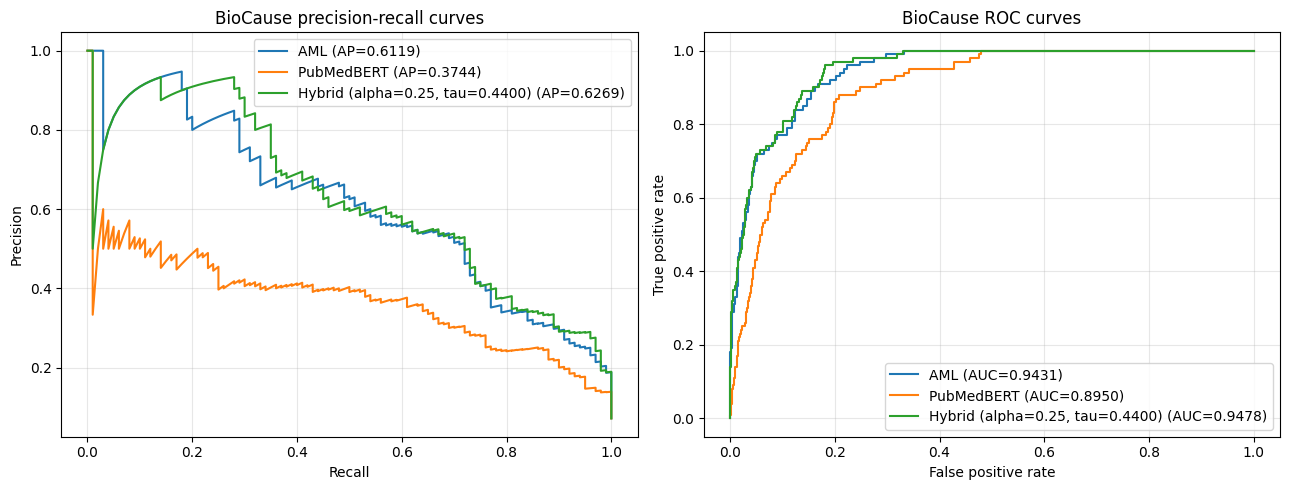

In [11]:
# Section 4: Precision-Recall & ROC Curves
hybrid_probs_recomputed = dl_utils.fuse_probabilities(
    df_aml['aml_prob'].to_numpy(), df_dl['dl_prob'].to_numpy(), selected_alpha
)
assert np.allclose(hybrid_probs_recomputed, df_hybrid['hybrid_prob'].to_numpy(), atol=1e-6)
if np.isclose(selected_alpha, 0.0):
    assert np.allclose(hybrid_probs_recomputed, df_aml['aml_prob'].to_numpy(), atol=1e-6)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
curve_streams = [
    ('AML', df_aml['aml_prob'].to_numpy()),
    ('PubMedBERT', df_dl['dl_prob'].to_numpy()),
    (f'Hybrid (alpha={selected_alpha:.2f}, tau={selected_tau:.4f})', hybrid_probs_recomputed),
]
for name, probabilities in curve_streams:
    precision, recall, _ = precision_recall_curve(y_true_bio, probabilities)
    axes[0].plot(recall, precision, label=f'{name} (AP={average_precision_score(y_true_bio, probabilities):.4f})')
    fpr, tpr, _ = roc_curve(y_true_bio, probabilities)
    axes[1].plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_true_bio, probabilities):.4f})')
axes[0].set(xlabel='Recall', ylabel='Precision', title='BioCause precision-recall curves')
axes[1].set(xlabel='False positive rate', ylabel='True positive rate', title='BioCause ROC curves')
for axis in axes:
    axis.legend(loc='best')
    axis.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'dl_biocause_pr_roc_curves.png', dpi=300)
plt.show()


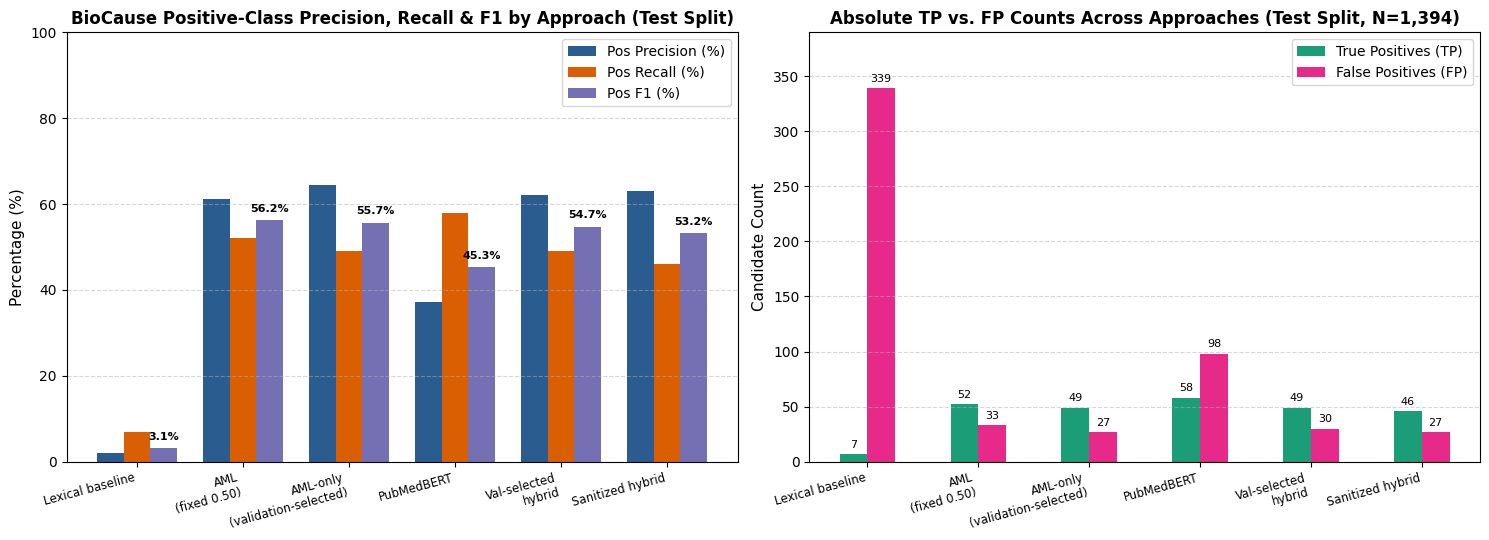

In [12]:
# Section 4b: Comparative Model Benchmark Plots (AML-5 Style)
plot_df = df_benchmark.copy()
x = np.arange(len(plot_df))
width = 0.25
short_labels = [m.replace(' (', '\n(').replace('Validation-selected ', 'Val-selected\n') for m in plot_df['Model Paradigm']]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Left: Precision, Recall, and Positive F1 (%)
p_bars = axes[0].bar(x - width, plot_df['Pos Precision'] * 100.0, width, label='Pos Precision (%)', color='#2b5c8f')
r_bars = axes[0].bar(x, plot_df['Pos Recall'] * 100.0, width, label='Pos Recall (%)', color='#d95f02')
f1_bars = axes[0].bar(x + width, plot_df['Pos F1'] * 100.0, width, label='Pos F1 (%)', color='#7570b3')
for bar in f1_bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2.0, h + 1.5, f'{h:.1f}%', ha='center', va='bottom', fontsize=8, fontweight='bold')
axes[0].set_ylabel('Percentage (%)', fontsize=11)
axes[0].set_title('BioCause Positive-Class Precision, Recall & F1 by Approach (Test Split)', fontsize=12, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(short_labels, fontsize=8.5, rotation=15, ha='right')
axes[0].set_ylim(0, 100)
axes[0].legend(frameon=True)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Right: Absolute True Positives (TP) vs False Positives (FP)
tp_bars = axes[1].bar(x - width / 2.0, plot_df['TP'], width, label='True Positives (TP)', color='#1b9e77')
fp_bars = axes[1].bar(x + width / 2.0, plot_df['FP'], width, label='False Positives (FP)', color='#e7298a')
for bar in (*tp_bars, *fp_bars):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2.0, h + 4, f'{int(h)}', ha='center', va='bottom', fontsize=8)
axes[1].set_ylabel('Candidate Count', fontsize=11)
axes[1].set_title('Absolute TP vs. FP Counts Across Approaches (Test Split, N=1,394)', fontsize=12, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(short_labels, fontsize=8.5, rotation=15, ha='right')
axes[1].set_ylim(0, max(plot_df['FP'].max(), plot_df['TP'].max()) * 1.15)
axes[1].legend(frameon=True)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(REPORTS_DIR / 'dl_biocause_model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


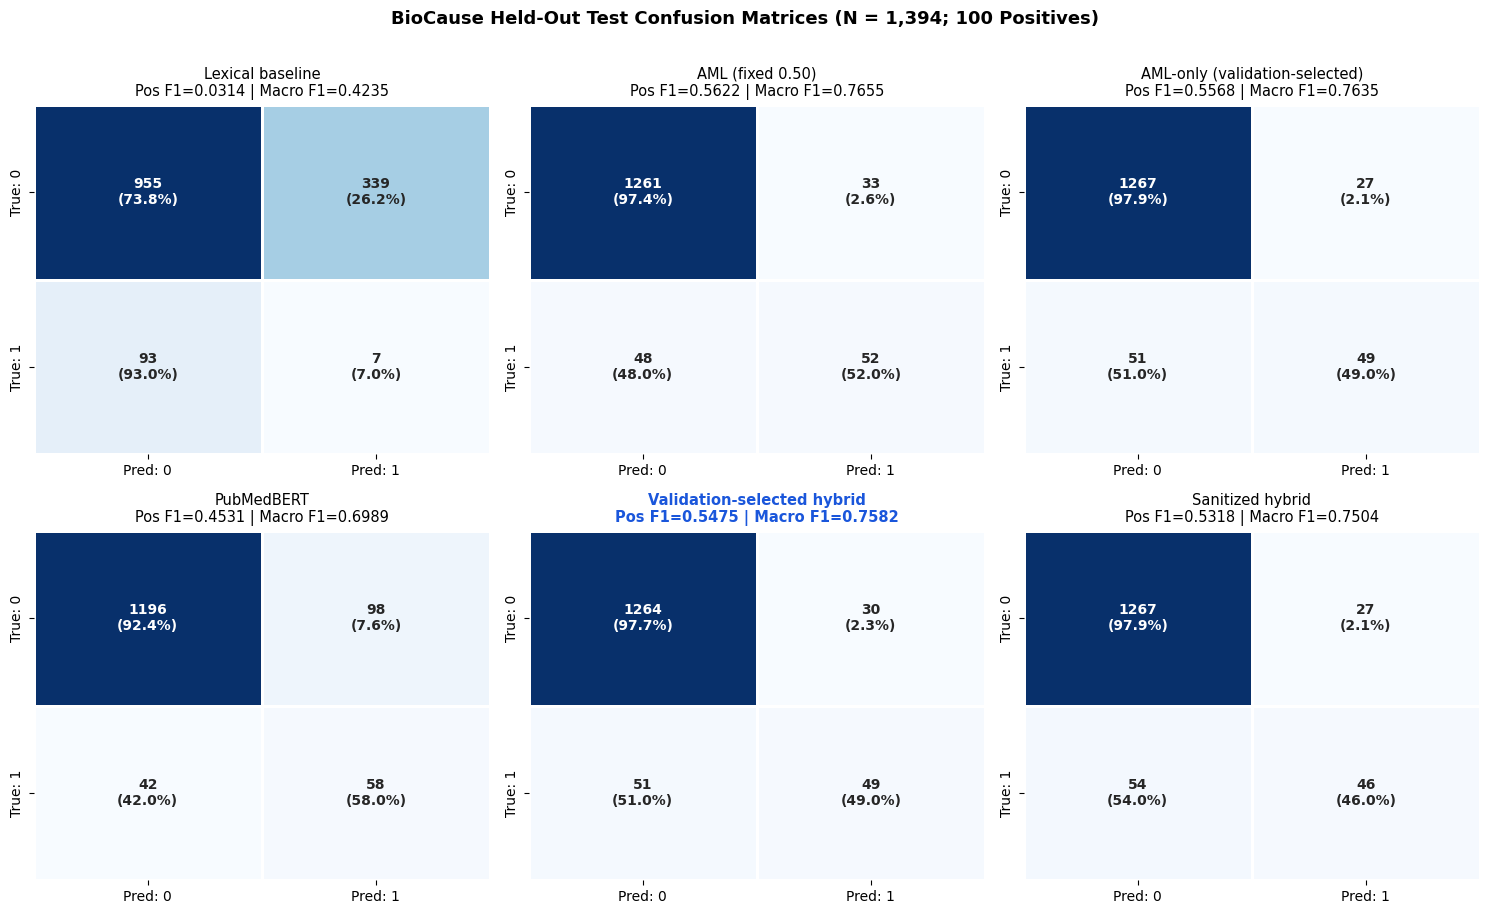

In [13]:
# Section 4c: Visual Confusion Matrix Heatmaps Across All Evaluated Models
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (_, row) in zip(axes.flat, df_benchmark.iterrows()):
    cm_arr = np.array(row['Confusion Matrix'], dtype=int)
    row_sums = cm_arr.sum(axis=1, keepdims=True)
    cm_pct = np.divide(cm_arr, row_sums, out=np.zeros_like(cm_arr, dtype=float), where=row_sums > 0) * 100.0
    annot = np.array([
        [f'{cm_arr[i, j]}\n({cm_pct[i, j]:.1f}%)' for j in range(cm_arr.shape[1])]
        for i in range(cm_arr.shape[0])
    ])
    sns.heatmap(
        cm_arr,
        annot=annot,
        fmt='',
        cmap='Blues',
        cbar=False,
        ax=ax,
        xticklabels=['Pred: 0', 'Pred: 1'],
        yticklabels=['True: 0', 'True: 1'],
        linewidths=0.8,
        linecolor='white',
        annot_kws={'size': 10, 'weight': 'bold'},
    )
    is_best = row['Model Paradigm'] == 'Validation-selected hybrid'
    ax.set_title(
        f"{row['Model Paradigm']}\nPos F1={row['Pos F1']:.4f} | Macro F1={row['Macro F1']:.4f}",
        fontsize=10.5,
        fontweight='bold' if is_best else 'normal',
        color='#1A56DB' if is_best else 'black',
    )

fig.suptitle('BioCause Held-Out Test Confusion Matrices (N = 1,394; 100 Positives)', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(REPORTS_DIR / 'dl_biocause_confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()


In [7]:
# Section 5: Executed Ablation Studies
import gc
import inspect
import math
import re
import shutil
import torch
from transformers import AutoModelForSequenceClassification, Trainer, DataCollatorWithPadding

train_ab = pd.read_csv(DATA_DIR / 'dl_biocause_train.csv')
val_ab = pd.read_csv(DATA_DIR / 'dl_biocause_val.csv')
test_ab = pd.read_csv(DATA_DIR / 'dl_biocause_test.csv')
assert [len(train_ab), len(val_ab), len(test_ab)] == [9928, 1884, 1394]
assert test_ab['candidate_id'].tolist() == df_test_manifest['candidate_id'].tolist()

n_pos_train_ab = int((train_ab['label'] == 1).sum())
n_neg_train_ab = int((train_ab['label'] == 0).sum())
pos_weight_ab = dl_utils.calculate_dynamic_class_weight(
    n_negative=n_neg_train_ab,
    n_positive=n_pos_train_ab,
)
assert np.isclose(pos_weight_ab, 9307 / 621)
mean_class_weight_ab = float((n_neg_train_ab * 1.0 + n_pos_train_ab * pos_weight_ab) / len(train_ab))
assert np.isclose(mean_class_weight_ab, 2.0 * n_neg_train_ab / len(train_ab))

if dl_metrics_meta is not None and 'test_overall' in dl_metrics_meta:
    assert np.isclose(float(dl_metrics_meta['test_overall']['positive_f1']), eval_dl['Pos F1'], atol=1e-4)
best_model_cfg = ROOT_DIR / 'DL' / 'models' / 'biocause_pubmedbert_best' / 'config.json'
if best_model_cfg.is_file():
    assert int(json.loads(best_model_cfg.read_text()).get('num_labels', 2)) == 2

class BioCauseDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels, tokenizer, max_length):
        encoded = tokenizer(
            list(texts),
            max_length=max_length,
            truncation=True,
        )
        self._input_ids = encoded['input_ids']
        self._attention_mask = encoded['attention_mask']
        self._labels = [int(y) for y in labels]

    def __len__(self):
        return len(self._labels)

    def __getitem__(self, idx):
        if isinstance(idx, str):
            if idx == 'input_ids':
                return self._input_ids
            if idx == 'attention_mask':
                return self._attention_mask
            if idx == 'labels':
                return self._labels
            raise KeyError(idx)
        return {
            'input_ids': self._input_ids[idx],
            'attention_mask': self._attention_mask[idx],
            'labels': self._labels[idx],
        }

def compute_ablation_metrics(eval_pred):
    logits, labels = eval_pred
    if isinstance(logits, tuple):
        logits = logits[0]
    assert logits.shape[-1] == 2
    predictions = np.argmax(logits, axis=-1)
    _, _, f1, _ = precision_recall_fscore_support(
        labels, predictions, labels=[0, 1], zero_division=0
    )
    macro_f1 = float(np.mean(f1))
    return {
        'accuracy': float(accuracy_score(labels, predictions)),
        'f1_0': float(f1[0]),
        'f1_1': float(f1[1]),
        'positive_f1': float(f1[1]),
        'macro_f1': macro_f1,
        'f1': macro_f1,
    }

def logits_to_pos_probs(raw_logits):
    logits = raw_logits[0] if isinstance(raw_logits, tuple) else raw_logits
    assert logits.ndim == 2 and logits.shape[1] == 2 and np.isfinite(logits).all()
    logits_f64 = logits.astype(np.float64)
    shifted = logits_f64 - np.max(logits_f64, axis=1, keepdims=True)
    exp_l = np.exp(shifted)
    probs = exp_l / np.sum(exp_l, axis=1, keepdims=True)
    assert np.isfinite(probs).all() and np.allclose(probs.sum(axis=1), 1.0)
    pos_probs = probs[:, 1]
    assert ((pos_probs >= 0.0) & (pos_probs <= 1.0)).all()
    return pos_probs

def build_candidate_thresholds(probs):
    uniform_grid = np.round(np.arange(0.01, 1.00, 0.01), 4)
    quantile_grid = np.round(np.clip(np.quantile(probs, np.linspace(0.01, 0.99, 99)), 0.01, 0.99), 4)
    combined = np.unique(np.concatenate([uniform_grid, quantile_grid]))
    combined = combined[(combined > 0.0) & (combined < 1.0)]
    return [float(t) for t in np.sort(combined)]

def evaluate_threshold(y_true, y_prob, tau):
    pred = y_prob >= float(tau)
    y_pos = y_true == 1
    tp = int(np.sum(pred & y_pos))
    fp = int(np.sum(pred & ~y_pos))
    fn = int(np.sum(~pred & y_pos))
    tn = int(len(y_true) - tp - fp - fn)
    pos_p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    pos_r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    pos_f1 = (2.0 * pos_p * pos_r / (pos_p + pos_r)) if (pos_p + pos_r) > 0 else 0.0
    neg_p = tn / (tn + fn) if (tn + fn) > 0 else 0.0
    neg_r = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    neg_f1 = (2.0 * neg_p * neg_r / (neg_p + neg_r)) if (neg_p + neg_r) > 0 else 0.0
    macro_f1 = 0.5 * (neg_f1 + pos_f1)
    return {
        'threshold': float(tau),
        'positive_predictions': int(tp + fp),
        'validation_positive_precision': float(pos_p),
        'validation_positive_recall': float(pos_r),
        'validation_positive_f1': float(pos_f1),
        'validation_macro_f1': float(macro_f1),
    }

class AblationTrainer(Trainer):
    def __init__(self, *args, class_weights=None, mean_class_weight=1.0, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights
        self.mean_class_weight = float(mean_class_weight)

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs['labels']
        model_inputs = {k: v for k, v in inputs.items() if k != 'labels'}
        outputs = model(**model_inputs)
        logits = outputs.logits
        assert logits.shape[-1] == 2
        assert labels.device == logits.device and labels.dtype in (torch.int32, torch.int64, torch.long)
        per_sample_loss = torch.nn.functional.cross_entropy(
            logits.float(), labels, reduction='none'
        )
        if self.class_weights is not None:
            weights = self.class_weights.to(device=logits.device, dtype=torch.float32)
            loss = (per_sample_loss * weights[labels]).mean() / self.mean_class_weight
        else:
            loss = per_sample_loss.mean()
        assert torch.isfinite(loss).all(), f'Non-finite ablation training loss: {loss}'
        return (loss, outputs) if return_outputs else loss

def run_ablation(label, use_markers, weighted):
    dl_utils.set_seed(42)
    device = dl_utils.get_device()
    if use_markers:
        train_texts = train_ab['marked_text']
        val_texts = val_ab['marked_text']
        test_texts = test_ab['marked_text']
    else:
        strip_markers = lambda s: s.str.replace(r'\s*\[/?E[12]\]\s*', ' ', regex=True).str.replace(r'\s+', ' ', regex=True).str.strip()
        train_texts = strip_markers(train_ab['marked_text'])
        val_texts = strip_markers(val_ab['marked_text'])
        test_texts = strip_markers(test_ab['marked_text'])
        for split_series in (train_texts, val_texts, test_texts):
            assert not split_series.str.contains(r'\[/?E[12]\]', regex=True).any()

    tok = dl_utils.prepare_tokenizer_and_inputs(
        checkpoint_name=dl_utils.PUBMEDBERT_CHECKPOINT,
        max_length=384,
        additional_special_tokens=dl_utils.ENTITY_MARKERS if use_markers else None,
        token=False,
    )
    if use_markers:
        assert all(
            tok.convert_tokens_to_ids(m) not in (None, tok.unk_token_id)
            for m in dl_utils.ENTITY_MARKERS
        )
    else:
        assert set(dl_utils.ENTITY_MARKERS).isdisjoint(set(tok.get_vocab().keys()))

    try:
        model = AutoModelForSequenceClassification.from_pretrained(
            dl_utils.PUBMEDBERT_CHECKPOINT, num_labels=2, local_files_only=True
        )
    except Exception:
        model = AutoModelForSequenceClassification.from_pretrained(
            dl_utils.PUBMEDBERT_CHECKPOINT, num_labels=2, token=False
        )
    if use_markers:
        dl_utils.resize_model_embeddings_for_tokenizer(model, tok)
    model.to(device)
    assert model.get_input_embeddings().weight.shape[0] == len(tok)

    train_ds = BioCauseDataset(train_texts, train_ab['label'], tok, 384)
    val_ds = BioCauseDataset(val_texts, val_ab['label'], tok, 384)
    test_ds = BioCauseDataset(test_texts, test_ab['label'], tok, 384)

    safe_slug = re.sub(r'[^a-z0-9_]+', '_', label.lower()).strip('_')
    ckpt_dir = ROOT_DIR / 'DL' / 'checkpoints' / f'ablation_{safe_slug}'
    shutil.rmtree(ckpt_dir, ignore_errors=True)
    ckpt_dir.mkdir(parents=True, exist_ok=True)

    cuda_avail = torch.cuda.is_available()
    mps_avail = hasattr(torch.backends, 'mps') and torch.backends.mps.is_available()
    fp16_enabled = bool(cuda_avail and not mps_avail)
    args = dl_utils.get_training_arguments(
        output_dir=str(ckpt_dir),
        num_epochs=3,
        batch_size=8,
        gradient_accumulation_steps=1,
        learning_rate=1e-5,
        weight_decay=0.01,
        fp16=fp16_enabled,
        eval_strategy='epoch',
        save_total_limit=3,
    )
    args.per_device_eval_batch_size = 16
    args.max_grad_norm = 1.0
    args.load_best_model_at_end = False
    args.metric_for_best_model = 'eval_f1_1'
    args.greater_is_better = True
    args.save_total_limit = 3
    total_train_steps = 3 * max(1, math.ceil(len(train_ds) / 8))
    args.warmup_steps = math.ceil(0.1 * total_train_steps)

    class_weights_tensor = torch.tensor([1.0, pos_weight_ab], dtype=torch.float32) if weighted else None
    trainer_kwargs = {
        'model': model,
        'args': args,
        'train_dataset': train_ds,
        'eval_dataset': val_ds,
        'data_collator': DataCollatorWithPadding(tokenizer=tok),
        'compute_metrics': compute_ablation_metrics,
        'class_weights': class_weights_tensor,
        'mean_class_weight': mean_class_weight_ab if weighted else 1.0,
    }
    sig = inspect.signature(Trainer.__init__)
    if 'processing_class' in sig.parameters:
        trainer_kwargs['processing_class'] = tok
    elif 'tokenizer' in sig.parameters:
        trainer_kwargs['tokenizer'] = tok

    trainer = AblationTrainer(**trainer_kwargs)
    trainer.train()

    epoch_logs = [
        {
            'epoch': float(entry['epoch']) if entry.get('epoch') is not None else 0.0,
            'step': int(entry['step']),
            'validation_loss': float(entry['eval_loss']),
        }
        for entry in trainer.state.log_history
        if 'eval_loss' in entry and 'eval_f1_1' in entry
    ]
    assert len(epoch_logs) == 3, f'{label}: Expected 3 epoch evaluations, got {len(epoch_logs)}'
    assert len({e['step'] for e in epoch_logs}) == 3, f'{label}: Duplicate global steps in epoch logs'

    ckpt_by_step = {}
    for p in ckpt_dir.iterdir():
        if p.is_dir() and p.name.startswith('checkpoint-'):
            suffix = p.name[len('checkpoint-'):]
            if not suffix.isdigit():
                raise RuntimeError(f'{label}: Ambiguous checkpoint directory name: {p.name}')
            step_num = int(suffix)
            if step_num in ckpt_by_step:
                raise RuntimeError(f'{label}: Duplicate checkpoint directory for step {step_num}')
            ckpt_by_step[step_num] = p

    missing_steps = [e['step'] for e in epoch_logs if e['step'] not in ckpt_by_step]
    if missing_steps:
        raise RuntimeError(f'{label}: Missing epoch checkpoint(s) for step(s) {missing_steps}')
    for idx_ep, e in enumerate(epoch_logs, start=1):
        if e['epoch'] == 0.0:
            e['epoch'] = float(idx_ep)
        e['checkpoint_dir'] = str(ckpt_by_step[e['step']])

    val_labels_arr = val_ab['label'].to_numpy()
    joint_epoch_results = []
    for e in epoch_logs:
        ckpt_model = AutoModelForSequenceClassification.from_pretrained(e['checkpoint_dir'], local_files_only=True)
        ckpt_model.to(device)
        ckpt_model.eval()
        trainer.model = ckpt_model
        val_out = trainer.predict(val_ds)
        assert np.array_equal(val_out.label_ids, val_labels_arr)
        val_probs = logits_to_pos_probs(val_out.predictions)
        ckpt_thresh_records = [evaluate_threshold(val_labels_arr, val_probs, tau) for tau in build_candidate_thresholds(val_probs)]
        best_ckpt_tau = max(
            ckpt_thresh_records,
            key=lambda r: (
                round(r['validation_positive_f1'], 8),
                round(r['validation_macro_f1'], 8),
                -round(abs(r['threshold'] - 0.50), 6),
                round(r['threshold'], 6),
            ),
        )
        joint_epoch_results.append({
            'epoch': e['epoch'],
            'step': e['step'],
            'validation_loss': e['validation_loss'],
            'best_threshold': float(best_ckpt_tau['threshold']),
            'validation_positive_f1': float(best_ckpt_tau['validation_positive_f1']),
            'validation_macro_f1': float(best_ckpt_tau['validation_macro_f1']),
            'checkpoint_dir': e['checkpoint_dir'],
        })
        del ckpt_model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    selected_epoch = max(
        joint_epoch_results,
        key=lambda r: (
            round(r['validation_positive_f1'], 8),
            round(r['validation_macro_f1'], 8),
            -round(r['validation_loss'], 8),
            -round(abs(r['best_threshold'] - 0.50), 6),
            round(r['best_threshold'], 6),
            -float(r['epoch']),
        ),
    )
    best_ckpt = str(selected_epoch['checkpoint_dir'])
    frozen_tau = float(selected_epoch['best_threshold'])
    assert best_ckpt and Path(best_ckpt).exists(), f'Missing best checkpoint for {label}'

    selected_model = AutoModelForSequenceClassification.from_pretrained(best_ckpt, local_files_only=True)
    selected_model.to(device)
    selected_model.eval()
    assert selected_model.config.num_labels == 2
    assert selected_model.get_input_embeddings().weight.shape[0] == len(tok)
    trainer.model = selected_model

    test_out = trainer.predict(test_ds)
    test_probs = logits_to_pos_probs(test_out.predictions)
    test_preds = (test_probs >= frozen_tau).astype(int)

    metrics_row = get_binary_metrics(label, test_ab['label'].to_numpy(), test_preds, test_probs, threshold=frozen_tau)
    metrics_row['Status'] = 'completed' if (metrics_row['TP'] + metrics_row['FP']) > 0 else 'completed_zero_positive_predictions'
    metrics_row['Selected_Checkpoint'] = Path(best_ckpt).name
    metrics_row['Selected_Epoch'] = float(selected_epoch['epoch'])
    metrics_row['Val_Pos_F1'] = round(float(selected_epoch['validation_positive_f1']), 4)
    metrics_row['Val_Macro_F1'] = round(float(selected_epoch['validation_macro_f1']), 4)

    del trainer, model, selected_model
    shutil.rmtree(ckpt_dir, ignore_errors=True)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return metrics_row

def format_static_ablation_row(metrics_dict, ablation_name, val_pos_f1=None, val_macro_f1=None):
    row = dict(metrics_dict)
    row['Ablation'] = ablation_name
    row['Status'] = 'completed' if (row['TP'] + row['FP']) > 0 else 'completed_zero_positive_predictions'
    row['Selected_Checkpoint'] = '-'
    row['Selected_Epoch'] = '-'
    row['Val_Pos_F1'] = round(float(val_pos_f1), 4) if val_pos_f1 is not None else None
    row['Val_Macro_F1'] = round(float(val_macro_f1), 4) if val_macro_f1 is not None else None
    return row

full_dl_row = format_static_ablation_row(
    eval_dl,
    'Full model with markers and weighted loss',
    val_pos_f1=dl_metrics_meta.get('best_val_positive_f1') if dl_metrics_meta else fusion_config.get('dl_only_validation_metrics', {}).get('positive_f1'),
    val_macro_f1=dl_metrics_meta.get('best_val_macro_f1') if dl_metrics_meta else fusion_config.get('dl_only_validation_metrics', {}).get('macro_f1'),
)
if dl_metrics_meta is not None:
    full_dl_row['Selected_Checkpoint'] = dl_metrics_meta.get('selected_checkpoint_name', '-')
    full_dl_row['Selected_Epoch'] = dl_metrics_meta.get('selected_epoch', '-')

aml_val_meta = fusion_config.get('aml_only_validation_metrics', {})
hyb_val_meta = fusion_config.get('validation_metrics', {})

ablation_rows = [
    full_dl_row,
    run_ablation('No entity markers', use_markers=False, weighted=True) | {'Ablation': 'No entity markers'},
    run_ablation('Unweighted loss', use_markers=True, weighted=False) | {'Ablation': 'Entity markers and unweighted loss'},
    format_static_ablation_row(eval_aml_fixed, 'Pure AML (fixed 0.50)'),
    format_static_ablation_row(
        eval_aml_val,
        'AML-only validation-selected threshold',
        val_pos_f1=aml_val_meta.get('positive_f1'),
        val_macro_f1=aml_val_meta.get('macro_f1'),
    ),
    format_static_ablation_row(
        eval_hybrid_raw,
        'Validation-selected hybrid',
        val_pos_f1=hyb_val_meta.get('positive_f1'),
        val_macro_f1=hyb_val_meta.get('macro_f1'),
    ),
    format_static_ablation_row(eval_hybrid_san, 'Sanitized hybrid (linguistic filtering)'),
]
df_ablations = pd.DataFrame(ablation_rows)
lead_cols = ['Ablation', 'Status', 'Selected_Checkpoint', 'Selected_Epoch', 'Threshold', 'Val_Pos_F1', 'Val_Macro_F1']
ablation_cols = lead_cols + [
    c for c in df_ablations.columns if c not in (*lead_cols, 'Model Paradigm')
]
df_ablations = df_ablations[ablation_cols]
df_ablations.round(4)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect ide

Epoch,Training Loss,Validation Loss,Accuracy,F1 0,F1 1,Positive F1,Macro F1,F1
1,1.323303,1.649266,0.930467,0.963981,0.000000,0.000000,0.481991,0.481991
2,1.496494,1.598502,0.930467,0.963981,0.000000,0.000000,0.481991,0.481991
3,1.426675,1.655964,0.930467,0.963981,0.000000,0.000000,0.481991,0.481991


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (11 outputs left out)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,Ablation,Status,Selected_Checkpoint,Selected_Epoch,Threshold,Val_Pos_F1,Val_Macro_F1,TP,FP,FN,TN,Accuracy,Pos Precision,Pos Recall,Pos F1,Macro F1,ROC-AUC,PR-AUC,Confusion Matrix
0,Full model with markers and weighted loss,completed,checkpoint-3723,3.0,0.1600,0.4531,0.7021,58,98,42,1196,0.8996,0.3718,0.58,0.4531,0.6989,0.8950,0.3744,"[[1196, 98], [42, 58]]"
1,No entity markers,completed,checkpoint-2482,2.0,0.0593,0.2312,0.5506,60,244,40,1050,0.7963,0.1974,0.60,0.2970,0.5890,0.7980,0.1941,"[[1050, 244], [40, 60]]"
2,Entity markers and unweighted loss,completed,checkpoint-3723,3.0,0.0800,0.4558,0.7049,55,89,45,1205,0.9039,0.3819,0.55,0.4508,0.6991,0.8994,0.3743,"[[1205, 89], [45, 55]]"
3,Pure AML (fixed 0.50),completed,-,-,0.5000,NaN,NaN,52,33,48,1261,0.9419,0.6118,0.52,0.5622,0.7655,0.9431,0.6119,"[[1261, 33], [48, 52]]"
4,AML-only validation-selected threshold,completed,-,-,0.5200,0.5976,0.7844,49,27,51,1267,0.9440,0.6447,0.49,0.5568,0.7635,0.9431,0.6119,"[[1267, 27], [51, 49]]"
5,Validation-selected hybrid,completed,-,-,0.4400,0.6383,0.8071,49,30,51,1264,0.9419,0.6203,0.49,0.5475,0.7582,0.9478,0.6269,"[[1264, 30], [51, 49]]"
6,Sanitized hybrid (linguistic filtering),completed,-,-,0.4400,NaN,NaN,46,27,54,1267,0.9419,0.6301,0.46,0.5318,0.7504,0.9478,0.6269,"[[1267, 27], [54, 46]]"


In [8]:
# Section 6: Graph Edge Precision, Recall & F1
from IPython.display import display

gold_rels_path = DATA_DIR / 'biocause_relations.csv'
dag_edges_path = DATA_DIR / 'dl_biocause_hybrid_dag_edges.csv'
positive_rels_path = DATA_DIR / 'dl_biocause_hybrid_positive_relations.csv'
pruning_diag_path = DATA_DIR / 'dl_biocause_graph_pruning_diagnostics.json'

df_gold_rels = pd.read_csv(gold_rels_path, keep_default_na=False)
df_dag_edges = pd.read_csv(dag_edges_path)
df_pos_rels = pd.read_csv(positive_rels_path)
diag_data = json.loads(pruning_diag_path.read_text())

test_articles = set(df_test_manifest['article_id'].unique())
gold_test_rels = df_gold_rels[df_gold_rels['article_id'].isin(test_articles)].copy()

G_gold = nx.DiGraph()
for _, r in gold_test_rels.iterrows():
    G_gold.add_edge(f"{r['section_id']}_{r['cause_id']}", f"{r['section_id']}_{r['effect_id']}")

G_raw = nx.DiGraph()
for _, r in df_pos_rels.iterrows():
    G_raw.add_edge(f"{r['section_id']}_{r['cause_id']}", f"{r['section_id']}_{r['effect_id']}")

G_dag = nx.DiGraph()
for _, r in df_dag_edges.iterrows():
    G_dag.add_edge(r['source'], r['target'])

assert nx.is_directed_acyclic_graph(G_dag), 'Exported hybrid DAG graph contains cycles'
assert G_raw.number_of_edges() == int(diag_data['initial_candidate_edges']), (
    f"Raw graph edge count mismatch: {G_raw.number_of_edges()} vs {diag_data['initial_candidate_edges']}"
)
assert G_dag.number_of_edges() == int(diag_data['final_dag_edges']), (
    f"DAG edge count mismatch: {G_dag.number_of_edges()} vs {diag_data['final_dag_edges']}"
)
assert G_raw.number_of_edges() == G_dag.number_of_edges() + int(diag_data['pruned_edges_count']), (
    f"Pruning reconciliation failed: {G_raw.number_of_edges()} != {G_dag.number_of_edges()} + {diag_data['pruned_edges_count']}"
)

def eval_graph(G_g, G_p, stage):
    ge = set(G_g.edges())
    pe = set(G_p.edges())
    tp = len(ge & pe)
    fp = len(pe - ge)
    fn = len(ge - pe)
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    return {
        'Stage': stage,
        'Gold Edges': len(ge),
        'Extracted Edges': len(pe),
        'TP': tp,
        'FP': fp,
        'FN': fn,
        'Precision': round(p, 4),
        'Recall': round(r, 4),
        'F1': round(f1, 4),
        'Is DAG': nx.is_directed_acyclic_graph(G_p),
    }

df_edge_eval = pd.DataFrame([
    eval_graph(G_gold, G_raw, 'Raw Extracted Graph (Pre-Pruning)'),
    eval_graph(G_gold, G_dag, 'Acyclic Causal DAG (Post-Pruning)'),
])
display(df_edge_eval[['Stage', 'Gold Edges', 'Extracted Edges', 'TP', 'FP', 'FN', 'Precision', 'Recall', 'F1', 'Is DAG']])

pb = diag_data.get('pruning_breakdown', {})
df_pruning_summary = pd.DataFrame([{
    'Test Articles': len(test_articles),
    'Self-Loops Pruned': int(pb.get('self_loops', 0)),
    'Bidirectional Conflicts Pruned': int(pb.get('bidirectional_conflicts', 0)),
    'Cycle Feedback Edges Pruned': int(pb.get('directed_cycle_feedback', 0)),
    'Total Edges Pruned': int(diag_data.get('pruned_edges_count', 0)),
    'Final DAG Edges': int(G_dag.number_of_edges()),
    'DAG Verified': bool(nx.is_directed_acyclic_graph(G_dag)),
}])
display(df_pruning_summary)


,Stage,Gold Edges,Extracted Edges,TP,FP,FN,Precision,Recall,F1,Is DAG
0,Raw Extracted Graph (Pre-Pruning),100,73,46,27,54,0.6301,0.46,0.5318,False
1,Acyclic Causal DAG (Post-Pruning),100,69,46,23,54,0.6667,0.46,0.5444,True


,Test Articles,Self-Loops Pruned,Bidirectional Conflicts Pruned,Cycle Feedback Edges Pruned,Total Edges Pruned,Final DAG Edges,DAG Verified
0,4,0,4,0,4,69,True


/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


,Query (Illustrative Synthetic CPDs),Probability,Delta vs Baseline
0,Baseline Marginal P(Resistance = 1),0.4242,0.0000
1,Observational P(Resistance = 1 | Sensor = 1),0.7200,0.2958
2,Interventional P(Resistance = 1 | do(Regulator...,0.8500,0.4258


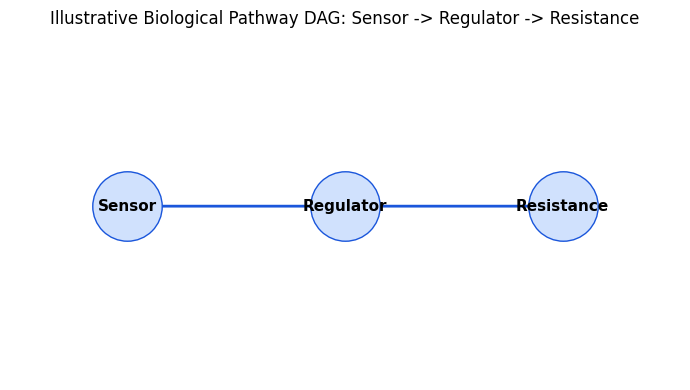

In [9]:
# Section 7: Causal Reasoning & Interventional Distributions
# Illustrative 3-node causal motif with synthetic CPDs demonstrating Pearl do-calculus.
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

bn = DiscreteBayesianNetwork([('Sensor', 'Regulator'), ('Regulator', 'Resistance')])

cpd_sensor = TabularCPD(variable='Sensor', variable_card=2, values=[[0.70], [0.30]])
cpd_regulator = TabularCPD(
    variable='Regulator', variable_card=2,
    values=[[0.85, 0.20],
            [0.15, 0.80]],
    evidence=['Sensor'], evidence_card=[2]
)
cpd_resistance = TabularCPD(
    variable='Resistance', variable_card=2,
    values=[[0.80, 0.15],
            [0.20, 0.85]],
    evidence=['Regulator'], evidence_card=[2]
)

bn.add_cpds(cpd_sensor, cpd_regulator, cpd_resistance)
assert bn.check_model()

infer = VariableElimination(bn)
p_res_base = float(infer.query(['Resistance']).values[1])
p_res_obs = float(infer.query(['Resistance'], evidence={'Sensor': 1}).values[1])

bn_do = DiscreteBayesianNetwork([('Regulator', 'Resistance')])
bn_do.add_nodes_from(bn.nodes())
cpd_reg_do = TabularCPD(variable='Regulator', variable_card=2, values=[[0.0], [1.0]])
bn_do.add_cpds(cpd_sensor, cpd_reg_do, cpd_resistance)
assert bn_do.check_model()
p_res_do = float(VariableElimination(bn_do).query(['Resistance']).values[1])

df_do_calculus = pd.DataFrame([
    {'Query (Illustrative Synthetic CPDs)': 'Baseline Marginal P(Resistance = 1)', 'Probability': round(p_res_base, 4), 'Delta vs Baseline': 0.0},
    {'Query (Illustrative Synthetic CPDs)': 'Observational P(Resistance = 1 | Sensor = 1)', 'Probability': round(p_res_obs, 4), 'Delta vs Baseline': round(p_res_obs - p_res_base, 4)},
    {'Query (Illustrative Synthetic CPDs)': 'Interventional P(Resistance = 1 | do(Regulator = 1))', 'Probability': round(p_res_do, 4), 'Delta vs Baseline': round(p_res_do - p_res_base, 4)},
])
display(df_do_calculus)

fig, ax = plt.subplots(figsize=(7, 4))
pos = {'Sensor': (0, 0.5), 'Regulator': (1, 0.5), 'Resistance': (2, 0.5)}
nx.draw_networkx_nodes(bn, pos, node_size=2500, node_color='#D0E1FD', edgecolors='#1A56DB', ax=ax)
nx.draw_networkx_labels(bn, pos, font_size=11, font_weight='bold', ax=ax)
nx.draw_networkx_edges(bn, pos, arrowstyle='->', arrowsize=25, edge_color='#1A56DB', width=2, ax=ax)
ax.set_title('Illustrative Biological Pathway DAG: Sensor -> Regulator -> Resistance', fontsize=12)
ax.margins(0.2)
plt.axis('off')
plt.tight_layout()
bn_fig_path = REPORTS_DIR / 'dl_biocause_bayesian_dag_motif.png'
plt.savefig(bn_fig_path, dpi=300)
plt.show()


In [10]:
# Section 8: Export Master Deliverables
master_benchmark_path = REPORTS_DIR / 'dl_final_benchmark_summary.csv'
df_benchmark.to_csv(master_benchmark_path, index=False)

master_ablation_path = REPORTS_DIR / 'dl_ablation_summary.csv'
df_ablations.to_csv(master_ablation_path, index=False)

df_bench_read = pd.read_csv(master_benchmark_path)
df_abl_read = pd.read_csv(master_ablation_path)

assert not df_bench_read.empty and len(df_bench_read) == len(df_benchmark), 'Benchmark read-back mismatch'
assert not df_abl_read.empty and len(df_abl_read) == len(df_ablations), 'Ablation read-back mismatch'
assert (REPORTS_DIR / 'dl_biocause_pr_roc_curves.png').exists(), 'Missing PR/ROC figure'
assert (REPORTS_DIR / 'dl_biocause_model_comparison.png').exists(), 'Missing Model Comparison figure'
assert (REPORTS_DIR / 'dl_biocause_confusion_matrices.png').exists(), 'Missing Confusion Matrices figure'
assert (REPORTS_DIR / 'dl_biocause_bayesian_dag_motif.png').exists(), 'Missing Bayesian DAG figure'


## 5. Expected Outputs & Evaluation Criteria

- `reports/dl_final_benchmark_summary.csv`: Master comparison table.
- `reports/dl_ablation_summary.csv`: Systematic ablation results table.
- High-resolution visual figures: Comparative PR curves, ROC curves, and illustrative Bayesian DAG motif.
- **Evaluation Criteria**: Rigorous empirical validation comparing Phase 1 AML baselines, Phase 2 DL models, and hybrid fusion across candidate extraction and graph synthesis.
